# AII 600. Lab 6: one point per precinct

Due before class, 7 October 2026.

Upload this notebook on Canvas, with every code cell executed and the output left in. Credit is on-time submission. I do not mark the lab.

Python kernel. R is allowed: switch to an R kernel and rewrite the code cells. Ask the tutor to translate `check`.

On 24 September 2026, [Meduza plotted the Duma party-list results](https://meduza.io/feature/2026/09/24/vybory-v-gosdumu-2026-samye-gryaznye-parlamentskie-vybory-epohi-putina): one point per precinct, turnout on $x$, United Russia share of valid votes on $y$. They did not publish the drawing code or the 82,124-row extract from the evening of 23 September (Leningrad oblast and the occupied regions were still missing). You will not get a pixel-identical figure, and you should not try.

You have a later freeze: 87,799 precincts with a party-list count, about 99% of 88,807, from the CEC protocols as compiled at [deg.zhizhin.xyz](https://deg.zhizhin.xyz/shpilkin.html) on 24 September. The right-hand mass will look a bit thicker than Meduza's. The 2003--2021 tables are the Shpilkin extracts in [Dmitry Kobak's elections repo](https://github.com/dkobak/elections).

| Ex. | Question | Tool |
|---|---|---|
| 1 | What does the 2026 scatter look like, and does extra turnout come with extra United Russia? | one point per precinct; OLS slope |
| 2 | What is the Moscow column? | subgroup, `is_deg` |
| 3 | Did the 2021 comet nucleus move? | 2021 vs 2026, a turnout band |
| 4 | Does 2026 look like Canada, Finland, or Klimek's Russia? | one Russia scatter vs a copied grid |
| 5 | How many precincts sit on a round percentage? | integer peaks, a stated rule |
| 6 | Does one line describe the cloud, and who sits off it? | least squares, residual, $R^2$ |
| 7 | Do the nucleus and the high-turnout precincts separate? | CLT, two-sample interval |

Work each numeric question on paper first, then type the expression. After you finish, copy whatever you cannot write from memory onto your cheat sheet.


## How this notebook works

1. Run the next cell once. It defines `check` and `plot_comet`.
2. Each exercise has an answer cell and a test cell. In the answer cell, replace every `None` and run it. Then run the test cell.
3. The test cell prints `ok  name` when that value is right to six decimals, `name is not right` when it is not (it never shows the target), and `replace None for name` when you left a `None`. Leave the output in the notebook.
4. Written cells have no test. Replace YOUR ANSWER HERE, then ask your tutor whether the reasoning holds. Prediction cells are for you: write them before you run the code, and do not go back and fix them.

Download these three into the same folder as this notebook. `pandas.read_csv` reads `.csv.gz` without extra steps. Do not download a fresh file from zhizhin: that dump refreshes, and the hashes here are for the freeze you were given.

- [duma_2026.csv.gz](https://vsokolov.org/courses/files/600/duma_2026.csv.gz)
- [duma_hist.csv.gz](https://vsokolov.org/courses/files/600/duma_hist.csv.gz)
- [lab6-klimek2012.png](https://vsokolov.org/courses/files/600/lab6-klimek2012.png)

Read the tables with `pandas`. If you open a CSV in Excel, the region names can look garbled (`ÐšÐµÐ¼...` instead of Кемеровская). The numbers are already right. Do not re-save the file from Excel. The filters in this lab match the Russian names as pandas reads them.

Turnout is $x=$ ballots issued / registered voters. United Russia is $y=$ party-list votes / valid party-list votes. Plot them as percents, $100x$ and $100y$. City names are in Russian: `город Москва` is the city, not `Московская область`; `город Санкт-Петербург`; `Чеченская Республика`.

`numpy`, `matplotlib`, and `pandas` are allowed. Ask the tutor for syntax; do the reading of the plot yourself.


In [1]:
from hashlib import sha256

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def check(name, value, expected, ndigits=6):
    if value is None:
        raise AssertionError(f"replace None for {name}")
    s = f"{round(float(value), ndigits):.{ndigits}f}"
    got = sha256(f"aii600-lab6|{name}|{s}".encode()).hexdigest()[:16]
    assert got == expected, f"{name} is not right"
    print("ok ", name)

def plot_comet(turnout, ur_share, ax=None, s=1, alpha=0.12, **kwargs):
    if ax is None:
        ax = plt.gca()
    ax.scatter(
        100 * np.asarray(turnout),
        100 * np.asarray(ur_share),
        s=s,
        alpha=alpha,
        linewidths=0,
        **kwargs,
    )
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Turnout (%)")
    ax.set_ylabel("United Russia, party list (%)")
    return ax


## Exercise 1: the 2026 cloud

Load `duma_2026.csv.gz`. Each row is one precinct. `issued` and `voters` give turnout; `ur_votes` and `valid` give United Russia's share of valid party-list votes. `is_deg` is 1 for remote-electronic totals (a handful of huge rows at 100% turnout), 0 for paper precincts.

**(a)** `n_2026` is the number of rows. `median_turnout` and `median_ur` are the unweighted precinct medians of the two shares (fractions, not percents).

**(b)** Ordinary least squares of `ur_share` on `turnout`, with intercept. `slope_ur_on_turnout` is the slope. If people who turn out were like people who stay home, extra turnout would not move the party share and the slope would be near 0. `np.polyfit(turnout, ur_share, 1)[0]` is the slope.

**(c)** Plot every precinct with `plot_comet`. You want a faint cloud, not a blob of ink: the helper already uses a small marker and low alpha.


Text(0.5, 1.0, 'Duma 2026')

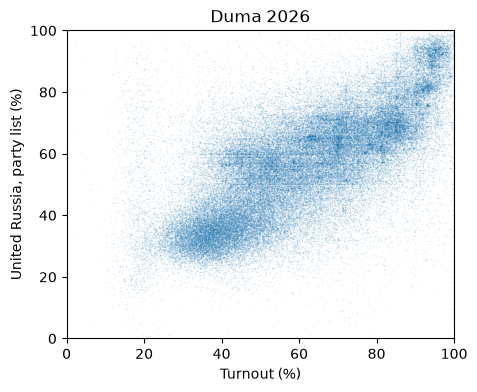

In [2]:
d26 = pd.read_csv("duma_2026.csv.gz")
d26["turnout"] = d26.issued / d26.voters
d26["ur_share"] = d26.ur_votes / d26.valid

n_2026 = len(d26)
median_turnout = d26.turnout.median()
median_ur = d26.ur_share.median()
slope_ur_on_turnout = np.polyfit(d26.turnout, d26.ur_share, 1)[0]

fig, ax = plt.subplots(figsize=(5, 4))
plot_comet(d26.turnout, d26.ur_share, ax)
ax.set_title("Duma 2026")


In [3]:
check("n_2026", n_2026, "cf171f2c15544e1e")
check("median_turnout", median_turnout, "6a341b1456d2c113")
check("median_ur", median_ur, "332de14cb4be6a3f")
check("slope_ur_on_turnout", slope_ur_on_turnout, "b619119d28d48978")
print("ok  ex1")


ok  n_2026
ok  median_turnout
ok  median_ur
ok  slope_ur_on_turnout
ok  ex1


**Write.** Look at the scatter, not the medians. Where is the dense part of the cloud, and what is the thick mass to the right? If the extra turnout on the right were people arriving independently of how they vote, what would you expect the slope in (b) to do? Two or three sentences.

YOUR ANSWER HERE: 
The dense part of the cloud is a compact nucleus at about 30–45% turnout and 30–40% United Russia. The thick mass to the right is a tail that climbs diagonally out of it to a second clump near 90–100% turnout and 85–95% United Russia, so the high-turnout precincts are also the precincts where United Russia is highest. If that extra turnout were people arriving independently of how they vote, United Russia's share would stay near the nucleus level as turnout rose, the cloud would run flat to the right, and the slope in (b) would be close to 0. Instead it is clearly positive.

## Exercise 2: the Moscow column

Meduza's new mark on the 2026 plot is a vertical strip of precincts to the *left* of the main cloud. That is paper voting in the city of Moscow after most of the city voted remotely.

Filter `d26` to `region == "город Москва"` and `is_deg == 0`. `n_moscow_paper`, `moscow_median_turnout`, and `moscow_median_ur` are the count and the two medians (fractions). Then `spb_median_turnout` for `город Санкт-Петербург` (all rows) and `chechnya_median_ur` for `Чеченская Республика`.

Plot the rest of the country in grey and Moscow paper on top in another colour, same `plot_comet` scales.


Text(0.5, 1.0, 'Duma 2026: Moscow paper in red')

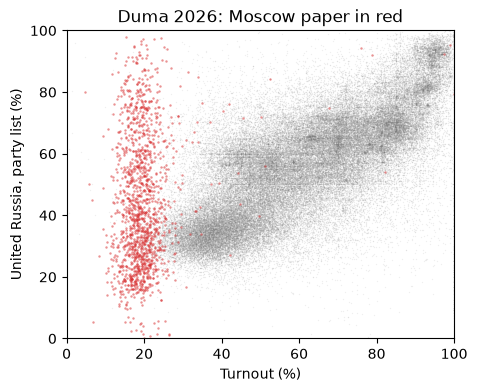

In [4]:
moscow_paper = d26[(d26.region == "город Москва") & (d26.is_deg == 0)]
n_moscow_paper = len(moscow_paper)
moscow_median_turnout = moscow_paper.turnout.median()
moscow_median_ur = moscow_paper.ur_share.median()
spb_median_turnout = d26[d26.region == "город Санкт-Петербург"].turnout.median()
chechnya_median_ur = d26[d26.region == "Чеченская Республика"].ur_share.median()

fig, ax = plt.subplots(figsize=(5, 4))
# rest of the country in grey, Moscow paper on top
rest = d26.drop(moscow_paper.index)
plot_comet(rest.turnout, rest.ur_share, ax, color="grey")
plot_comet(moscow_paper.turnout, moscow_paper.ur_share, ax, color="C3", s=3, alpha=0.5)
ax.set_title("Duma 2026: Moscow paper in red")

In [5]:
check("n_moscow_paper", n_moscow_paper, "f4cdaed68ce66c22")
check("moscow_median_turnout", moscow_median_turnout, "2ba7f9f0233b2c94")
check("moscow_median_ur", moscow_median_ur, "96e02f9092897263")
check("spb_median_turnout", spb_median_turnout, "b17946063a1ce773")
check("chechnya_median_ur", chechnya_median_ur, "e9e46bc565e5b851")
print("ok  ex2")


ok  n_moscow_paper
ok  moscow_median_turnout
ok  moscow_median_ur
ok  spb_median_turnout
ok  chechnya_median_ur
ok  ex2


**Write.** (a) Why did Moscow paper turnout fall, and why is the remaining cloud a vertical strip rather than a diagonal tail? One of those has a mechanical explanation in the lab text; the shape of the strip does not. Two sentences.

(b) Petersburg and Chechnya moved differently from Moscow. What did each do, in one sentence each?

YOUR ANSWER HERE
(a)

▎ Moscow paper turnout fell (median 19%, down from 33% in 2021) because most of the city's likely voters voted remotely and are counted in the electronic rows. That left the paper precincts with the voters who did not sign up for remote voting, a group that includes most people who do not vote at all. The lab text explains that drop but not the strip's shape: turnout is tightly bunched (half the precincts sit between 17% and 21%) while the United Russia share at that same turnout runs from about 10% to over 90%, and nothing in the remote-voting shift explains such a wide spread in party share without any climb in turnout.

(b)

▎ St. Petersburg moved up the diagonal rather than left: median turnout rose from 36% in 2021 to 53%, and United Russia from 32% to 56%. Chechnya did not move at all: median turnout stayed near 95% and United Russia near 93–97%, in the top-right corner both years.

## Exercise 3: 2021 vs 2026

Load `duma_hist.csv.gz`. It has `year`, `region`, `turnout`, `ur_share` as fractions for 2003, 2007, 2011, 2016, and 2021. Restrict to `year == 2021` for this exercise.

Meduza's reading of the 2021 plot is a comet: a nucleus around 35--40% turnout and 30% United Russia, and a tail that climbs with turnout. They treat the nucleus as the closest thing to an un-edited result, then note that this nucleus barely moved in 2026.

Take the nucleus to be precincts with turnout in $[0.30, 0.45]$, inclusive. `n_2021` is all 2021 rows. `n_nucleus_2021` and `n_nucleus_2026` are the counts in that band. `nucleus_ur_2021` and `nucleus_ur_2026` are the median United Russia shares inside it.

Side-by-side `plot_comet` for 2021 and 2026, same $x$ and $y$ limits.


**Predict**, before you run the cell. Will `nucleus_ur_2026` be within five percentage points of `nucleus_ur_2021`, or did the "honest" band jump with the official headline? One sentence.

YOUR PREDICTION HERE


<Axes: xlabel='Turnout (%)', ylabel='United Russia, party list (%)'>

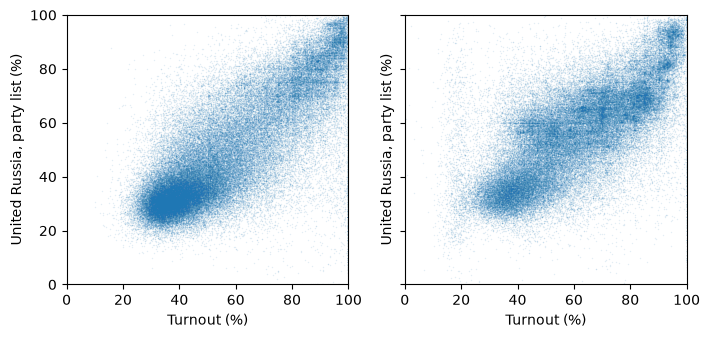

In [6]:
hist = pd.read_csv("duma_hist.csv.gz")
d21 = hist[hist.year == 2021]

nuc21 = d21[d21.turnout.between(0.30, 0.45)]
nuc26 = d26[d26.turnout.between(0.30, 0.45)]

n_2021 = len(d21)
n_nucleus_2021 = len(nuc21)
n_nucleus_2026 = len(nuc26)
nucleus_ur_2021 = nuc21.ur_share.median()
nucleus_ur_2026 = nuc26.ur_share.median()

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharex=True, sharey=True)
# 2021 on the left, 2026 on the right
plot_comet(d21.turnout, d21.ur_share, axes[0])
plot_comet(d26.turnout, d26.ur_share, axes[1])

In [7]:
check("n_2021", n_2021, "b7f6451bba36bc21")
check("n_nucleus_2021", n_nucleus_2021, "ae00eab27dfd5c8e")
check("n_nucleus_2026", n_nucleus_2026, "76a80aa5ad98cd1c")
check("nucleus_ur_2021", nucleus_ur_2021, "4b8f89596cd0de2f")
check("nucleus_ur_2026", nucleus_ur_2026, "a20f0a18bb20652c")
print("ok  ex3")


ok  n_2021
ok  n_nucleus_2021
ok  n_nucleus_2026
ok  nucleus_ur_2021
ok  nucleus_ur_2026
ok  ex3


**Write.** (a) How many points did the nucleus United Russia share move, and did the nucleus get smaller? Two sentences.

(b) Treating the nucleus as "true" is a modelling choice, not a theorem. Give one reason it could still be too high, and one reason the 2021--2026 comparison inside that band is still useful. Two sentences.

YOUR ANSWER HERE
(a)

▎ Inside the 30–45% band the median United Russia share rose from 32.5% in 2021 to 37.4% in 2026, a move of about 5 points, much smaller than the jump in the headline result. The nucleus did shrink, from 31,610 precincts (33% of all) to 18,008 (21%); about 4,000 of that loss is Moscow and St. Petersburg leaving the band, Moscow paper falling below it and St. Petersburg moving up the diagonal.

(b)

▎ The nucleus could still be too high because a count can be edited without inflating turnout (votes moved from other parties, or pressure on voters), so a low-turnout precinct is not automatically a clean one. The comparison is still useful because it applies the same rule to the same band in both years, so a bias that stays roughly constant cancels in the difference, and what remains says how far the low-turnout electorate moved compared with the headline.

## Exercise 4: one Russia panel, against the other countries

A non-Gaussian cloud is not, by itself, a fingerprint. The figure below is Meduza's copy of Klimek, Yegorov, Hanel, and Thurner, [PNAS 2012](https://www.pnas.org/doi/10.1073/pnas.1210722109): turnout vs the leader, one panel per country. Canada 2011 is two blobs (English- and French-speaking regions). Finland and Poland slope without a pile in the 100% corner. Russia 2011 and Uganda do have that corner (circled). Do not rebuild Canada, Finland, or Poland.

![Turnout versus leader share in twelve elections. Canada is bimodal; Finland and Poland slope without a 100% corner. Red circles mark Russia 2011, Russia 2012, and Uganda.](lab6-klimek2012.png)

Plot one scatter for Russia 2026, same axes as those panels: turnout on $x$, United Russia on $y$, both 0 to 100. `plot_comet` already uses those limits. Put it next to the grid and compare by eye.

Then, from `hist` and `d26`, Pearson's correlation of turnout with United Russia share in 2003, 2021, and 2026: `corr_2003`, `corr_2021`, `corr_2026`. The share of precincts with turnout above 0.8 in 2003 and in 2026: `share_turnout_gt80_2003`, `share_turnout_gt80_2026`.


Text(0.5, 1.0, 'Russia 2026')

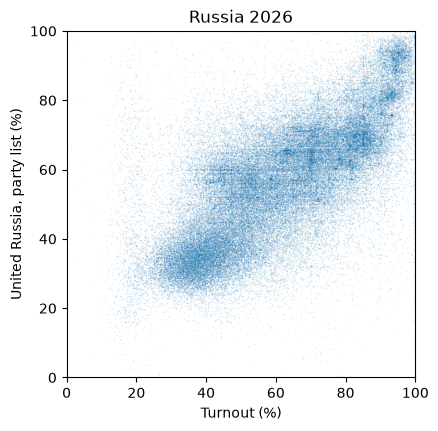

In [8]:
d03 = hist[hist.year == 2003]

corr_2003 = d03.turnout.corr(d03.ur_share)
corr_2021 = d21.turnout.corr(d21.ur_share)
corr_2026 = d26.turnout.corr(d26.ur_share)
share_turnout_gt80_2003 = (d03.turnout > 0.8).mean()
share_turnout_gt80_2026 = (d26.turnout > 0.8).mean()

fig, ax = plt.subplots(figsize=(4.5, 4.5))
# Russia 2026, same 0--100 box as the Klimek panels
plot_comet(d26.turnout, d26.ur_share, ax)
ax.set_title("Russia 2026")

In [9]:
check("corr_2003", corr_2003, "2dff4d65250b74f4")
check("corr_2021", corr_2021, "51acfb37b49d4142")
check("corr_2026", corr_2026, "136e695e4eff6089")
check("share_turnout_gt80_2003", share_turnout_gt80_2003, "e648d8e1f5803099")
check("share_turnout_gt80_2026", share_turnout_gt80_2026, "659d4b6b4b64ec9a")
print("ok  ex4")


ok  corr_2003
ok  corr_2021
ok  corr_2026
ok  share_turnout_gt80_2003
ok  share_turnout_gt80_2026
ok  ex4


**Write.** Put your 2026 plot next to the Klimek grid. Which of those twelve panels does it match, and which two does it not match (Canada; Finland or Poland)? A slope of turnout with the leader exists in honest countries too. What in your scatter is the thing those panels do not have? Two or three sentences.

YOUR ANSWER HERE
The 2026 scatter matches Russia '11 and Russia '12: a dense nucleus at moderate turnout with a tail climbing into the top-right corner. It does not match Canada, which is two blobs stacked at the same turnout with no slope, or Finland and Poland, which are compact clouds that slope a little but stop well short of 100%. The thing the honest panels lack is the clump at the 100/100 corner, about 1,500 precincts (1.7%) with turnout above 95% and United Russia above 90%, which a mixture of ordinary electorates does not produce.

## Exercise 5: round percentages

One fingerprint that does not appear in honest counting is a pile of precincts at 50.0%, 60.0%, 70.0%. Kobak, Shpilkin, and Pshenichnikov ([*Significance*, 2018](https://rss.onlinelibrary.wiley.com/doi/10.1111/j.1740-9713.2018.01141.x); the rule is in their [*Annals* paper](https://projecteuclid.org/euclid.aoas/1458909907)) call a reported percentage $p$ on a 0--100 scale *near-integer* when $|p-\mathrm{round}(p)|\le 0.05$. That is a 0.1-point window around each integer.

Meduza's headline count, about 1,300 precincts in 2021 to about 2,250 in 2026, is the *excess* over a Monte Carlo baseline, on their incomplete 82,124-row dump, with their threshold. You will not match 2,250. Compute the raw count on this freeze, with the rule above.

A precinct is near-integer on turnout if that rule holds for $100\times$ turnout, and the same for United Russia. `n_int_turnout_2026`, `n_int_ur_2026`, and `n_int_both_2026` are the 2026 counts. `n_int_both_2021` is the 2021 count where *both* are near-integer.

Plot two histograms of 2026, 0.25-point bins from 0 to 100: turnout percent, then United Russia percent. You should see spikes at the round numbers. `np.arange(0, 100.25, 0.25)` is a set of edges.


Text(0.5, 0, 'Percent, 0.25-point bins')

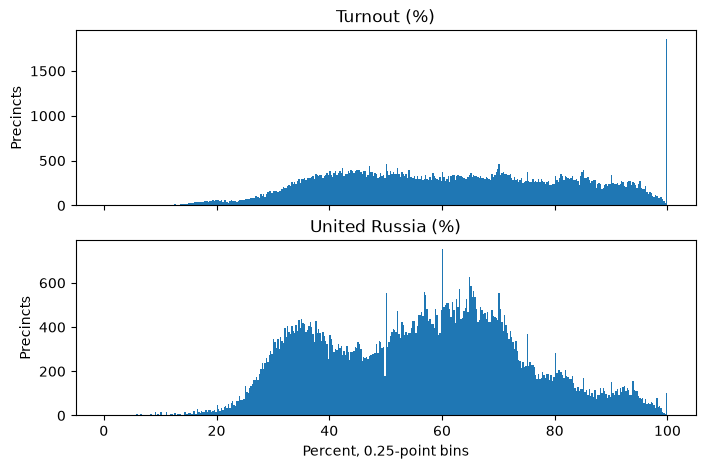

In [10]:
def near_integer(share, tol=0.05):
    p = 100 * np.asarray(share, float)
    return np.abs(p - np.round(p)) <= tol

int_t26 = near_integer(d26.turnout)
int_u26 = near_integer(d26.ur_share)

n_int_turnout_2026 = int_t26.sum()
n_int_ur_2026 = int_u26.sum()
n_int_both_2026 = (int_t26 & int_u26).sum()
n_int_both_2021 = (near_integer(d21.turnout) & near_integer(d21.ur_share)).sum()

edges = np.arange(0, 100.25, 0.25)
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
# turnout on top, United Russia below, bins of 0.25
axes[0].hist(100 * d26.turnout, bins=edges)
axes[0].set_ylabel("Precincts")
axes[0].set_title("Turnout (%)")
axes[1].hist(100 * d26.ur_share, bins=edges)
axes[1].set_ylabel("Precincts")
axes[1].set_title("United Russia (%)")
axes[1].set_xlabel("Percent, 0.25-point bins")

In [11]:
check("n_int_turnout_2026", n_int_turnout_2026, "e9a581753f149b49")
check("n_int_ur_2026", n_int_ur_2026, "9ce5e3435e75fc36")
check("n_int_both_2026", n_int_both_2026, "913ba482bdd2e764")
check("n_int_both_2021", n_int_both_2021, "8fa5d151b56bd8db")
print("ok  ex5")


ok  n_int_turnout_2026
ok  n_int_ur_2026
ok  n_int_both_2026
ok  n_int_both_2021
ok  ex5


**Write.** (a) Why can a *few* precincts land on 70.0 even when nobody touches the protocol, and why is a visible spike still a problem? Two sentences.

(b) Your `n_int_both_2026` is a raw count on a later, larger file. Why is it not Meduza's 2,250, and what would you still need in order to call it an *excess*? Two sentences.

YOUR ANSWER HERE
(a)

A precinct's share is a ratio of whole ballots, k/N, so some land exactly on a round value with nobody touching anything (7 of 10, 350 of 500), and simple fractions such as 1/2 and 3/5 come up more often than others, most of all in small precincts; that is why there is a small honest bump at 50 and a dip just below it. A visible spike is still a problem because that arithmetic predicts a modest bump you can work out from each precinct's N, not a bar like 60.0 standing about half again above its neighbours, which is what protocols written to a target percentage would produce.

(b)

My 1,604 is a raw count on a later and larger file (87,799 precincts, not 82,124) and includes every precinct that lands on a round number honestly, while Meduza's 2,250 is an excess over a Monte Carlo baseline on their dump with their own threshold, so the two numbers measure different things. To call mine an excess I would need that baseline: simulate each precinct's votes from a binomial with its own N and observed share, count how often the simulated precincts land near-integer, and subtract that expected count from 1,604.


## Exercise 6: one line, and who sits off it

The scatter is a regression. Turnout is $x$, United Russia share is $y$, and the conditional mean is a line, $\mu=a+bx$. Least squares is the Normal likelihood with that mean: it minimizes $\sum(y_i-a-bx_i)^2$. A negative residual $e_i=y_i-\hat y_i$ sits below the line.

**(a) Width.** One precinct is a coin. At share $0.57$ and $1600$ valid ballots, `se_one_precinct` $=\sqrt{0.57\times 0.43/1600}$. `sd_across_precincts` is `np.std` of every 2026 share (divide by $n$, not $n-1$). The first is how far one count wanders. The second is how wide the cloud is. If every precinct were the same coin, those two would be close.

**(b) The line.** On all of `d26`,

```python
X = np.c_[np.ones(len(d26)), d26.turnout.to_numpy()]
theta = np.linalg.lstsq(X, d26.ur_share.to_numpy(), rcond=None)[0]
```

`intercept` is `theta[0]`. `pred_at_40` and `pred_at_90` are the line at turnout $0.40$ and $0.90$: one row $[1, x]$ times `theta`. `r2` compares two squared losses, the line against predicting $\bar y$ for every precinct: $R^2=1-\mathrm{mean}(e^2)/\mathrm{mean}((y-\bar y)^2)$. Draw the line on the Exercise 1 scatter, in share units or in percent, your choice, same line.

**(c) Off the line.** `chechnya_mean_residual` is the mean residual in `Чеченская Республика`. `moscow_paper_r2` is $R^2$ from the same fit restricted to Moscow paper precincts (`город Москва` and `is_deg == 0`). A steep national slope can still be a bad description of one city.


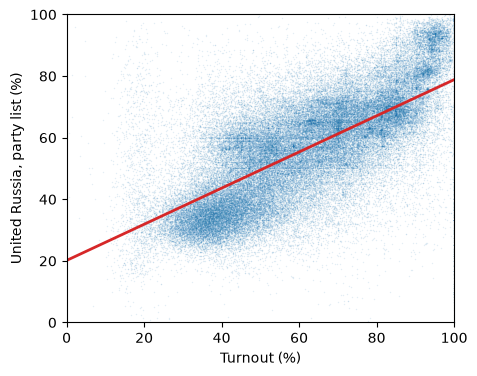

In [12]:
se_one_precinct = np.sqrt(0.57 * 0.43 / 1600)
sd_across_precincts = np.std(d26.ur_share)

X = np.c_[np.ones(len(d26)), d26.turnout.to_numpy()]
y = d26.ur_share.to_numpy()
theta = np.linalg.lstsq(X, y, rcond=None)[0]
e = y - X @ theta

intercept = theta[0]
pred_at_40 = np.array([1, 0.40]) @ theta
pred_at_90 = np.array([1, 0.90]) @ theta
r2 = 1 - np.mean(e**2) / np.mean((y - y.mean())**2)

is_chechnya = (d26.region == "Чеченская Республика").to_numpy()
chechnya_mean_residual = e[is_chechnya].mean()

is_mp = ((d26.region == "город Москва") & (d26.is_deg == 0)).to_numpy()
X_mp, y_mp = X[is_mp], y[is_mp]
theta_mp = np.linalg.lstsq(X_mp, y_mp, rcond=None)[0]
e_mp = y_mp - X_mp @ theta_mp
moscow_paper_r2 = 1 - np.mean(e_mp**2) / np.mean((y_mp - y_mp.mean())**2)

fig, ax = plt.subplots(figsize=(5, 4))
plot_comet(d26.turnout, d26.ur_share, ax)
# the fitted line, on the same 0--100 percent axes
xs = np.array([0, 1])
ax.plot(100 * xs, 100 * (theta[0] + theta[1] * xs), color="C3", lw=2)

In [13]:
check("se_one_precinct", se_one_precinct, "244afa63832b733f")
check("sd_across_precincts", sd_across_precincts, "422906310b30b258")
check("intercept", intercept, "3b47f62c7eebca1c")
check("pred_at_40", pred_at_40, "f78660f892be8851")
check("pred_at_90", pred_at_90, "b080e531e9d04aa2")
check("r2", r2, "cd03ac4f376cadf6")
check("chechnya_mean_residual", chechnya_mean_residual, "3978c57fe1c03c2c")
check("moscow_paper_r2", moscow_paper_r2, "3efe71303e13c563")
print("ok  ex6")


ok  se_one_precinct
ok  sd_across_precincts
ok  intercept
ok  pred_at_40
ok  pred_at_90
ok  r2
ok  chechnya_mean_residual
ok  moscow_paper_r2
ok  ex6


**Write.** (a) Your cloud is many times wider than `se_one_precinct`. What does that rule out: a single shared coin, with the scatter as binomial noise? One sentence.

(b) A precinct at 40% turnout with United Russia share 0.30 has residual `0.30 - pred_at_40`. Which side of the line is it on? Chechnya's mean residual is positive. What does a whole region above the national line tell you that the slope, by itself, does not? Two sentences.

(c) `moscow_paper_r2` is near zero while the national $R^2$ is not. The same tool, a straight line, is a summary of the country and a bad summary of that city. Which feature of the Moscow scatter, from Exercise 2, is the reason? One sentence.

YOUR ANSWER HERE
(a)

It rules out a single shared coin: binomial noise would spread the precincts by about 0.012, but the cloud's standard deviation is 0.178, about 14 times wider, so precincts genuinely differ in their United Russia share rather than scattering around one common value.

(b)

The residual is 0.30 − 0.436 = −0.136, so that precinct sits about 14 points below the line. Chechnya's mean residual of +0.157 means its precincts give United Russia about 16 points more than the national line predicts at their own turnout, which says the region's high share is not explained by its high turnout alone; the slope describes how share moves with turnout across the country and says nothing about which regions sit systematically above or below it.

(c)

Moscow paper precincts form a narrow vertical strip at about 17–21% turnout while United Russia ranges from about 10% to 90%, so there is almost no turnout variation for the line to use, and the spread in share is left almost entirely in the residuals.

## Exercise 7: two samples, one interval

In the lecture, two search algorithms each got 2500 requests. The click rates were $\hat p_1$ and $\hat p_2$, each with standard error $\sqrt{\hat p(1-\hat p)/n}$, and the difference had standard error $\sqrt{\mathrm{se}_1^2+\mathrm{se}_2^2}$. The interval for the difference missed zero. That comparison was a randomized assignment of requests.

Here the two samples are precincts you already plotted, not requests. The nucleus is turnout in $[0.30, 0.45]$. The tail is turnout above $0.8$. The number in each sample is the mean United Russia share, unweighted, one precinct one vote in the average.

One precinct's share is not a normal draw. The central limit theorem is about the average: with this many precincts, $\bar y$ is approximately normal, and

$$\mathrm{se}(\bar y)=\frac{s}{\sqrt{n}},\qquad s=\texttt{np.std(..., ddof=0)}.$$

A 95% interval is $\bar y\pm 1.96\,\mathrm{se}$. `mean_nucleus` and `mean_tail` are the two averages. `se_diff` is the standard error of `mean_tail - mean_nucleus`. `diff_lo` and `diff_hi` are the ends of that difference interval. Use $1.96$, not a rounded $2$.


In [14]:
nucleus = d26.loc[d26.turnout.between(0.30, 0.45), "ur_share"].to_numpy()
tail = d26.loc[d26.turnout > 0.8, "ur_share"].to_numpy()

se_nucleus = np.std(nucleus) / np.sqrt(len(nucleus))
se_tail = np.std(tail) / np.sqrt(len(tail))

mean_nucleus = nucleus.mean()
mean_tail = tail.mean()
se_diff = np.sqrt(se_nucleus**2 + se_tail**2)
diff_lo = (mean_tail - mean_nucleus) - 1.96 * se_diff
diff_hi = (mean_tail - mean_nucleus) + 1.96 * se_diff


In [15]:
check("mean_nucleus", mean_nucleus, "17d6e92d8c5d247e")
check("mean_tail", mean_tail, "4b5ad40386b3e78a")
check("se_diff", se_diff, "9ddec435cf970e4e")
check("diff_lo", diff_lo, "bb0190e309d0a009")
check("diff_hi", diff_hi, "0f1954554fe2ab8b")
print("ok  ex7")


ok  mean_nucleus
ok  mean_tail
ok  se_diff
ok  diff_lo
ok  diff_hi
ok  ex7


**Write.** (a) Do the two intervals for the means overlap, and does the interval for the difference contain 0? One sentence. You already have the pieces: each mean's interval is $\bar y\pm 1.96\,\mathrm{se}(\bar y)$.

(b) In the Google example the requests were assigned at random, so a gap that clears zero is a difference between algorithms. Turnout here was not assigned. What does an interval that misses zero say, and what does it not say? Two sentences.

(c) Four times as many precincts would halve `se_diff`. These files are already almost every precinct. What would a still narrower interval add, and what would it leave untouched? One sentence.

YOUR ANSWER HERE:
(a)

The two intervals do not overlap (about 0.408–0.412 for the nucleus against 0.731–0.735 for the tail), and the interval for the difference, 0.320 to 0.326, is nowhere near 0.

(b)

An interval that misses zero says the tail's average United Russia share really is about 32 points higher than the nucleus's, a gap far too large to be noise from which precincts happened to be counted. It does not say why: turnout was not assigned, so the gap could come from different regions, rural versus urban precincts, edited counts, or pressure on voters, and the interval cannot tell those apart.

(c)

A narrower interval would pin down the size of the gap more precisely, but it would leave untouched the question of why the gap exists, because more precincts reduce sampling noise, not confounding.


## Before you submit

- Restart the kernel and run every cell. Each test cell prints `ok`.
- Every YOUR PREDICTION HERE and YOUR ANSWER HERE is replaced.
- Cheat sheet check. Without looking, can you write: turnout and a party share from a protocol; $\mathrm{sd}(\hat p)=\sqrt{p(1-p)/n}$ for one precinct; $\mathrm{sd}(\bar y)=s/\sqrt{n}$ and a 95% interval $\bar y\pm 1.96\,s/\sqrt{n}$; the standard error of a difference, $\sqrt{\mathrm{se}_1^2+\mathrm{se}_2^2}$; $e_i=y_i-\hat y_i$ and which sign sits below the line; $R^2$ as squared error against the constant-mean prediction; what a positive slope of share on turnout would mean if extra ballots were independent of the party; why a vertical strip at low turnout is not the same as a diagonal tail; why honest integer vote counts can hit 50.0 sometimes, and why a pile at 70.0 is a different story? Whatever you cannot write goes on the sheet.
